In [1]:
%pip install numpy pandas matplotlib scikit-learn scipy yfinance

Note: you may need to restart the kernel to use updated packages.


In [5]:
import yfinance as yf
import pandas as pd

tickers = [
    "AAPL",
    "MSFT",
    "GOOGL",
    "BTC-USD",
    "ETH-USD",
    "GLD",
    "^GSPC"
]

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True
)

prices = data["Close"].copy()

print("Original prices shape:", prices.shape)
display(prices.head()) 

[*********************100%***********************]  7 of 7 completed


Original prices shape: (2192, 7)


Ticker,AAPL,BTC-USD,ETH-USD,GLD,GOOGL,MSFT,^GSPC
Date,,,,,,,
2020-01-01,NaN,7200.174316,130.802002,NaN,NaN,NaN,NaN
2020-01-02,72.271561,6985.470215,127.410179,143.949997,67.788933,151.544266,3257.850098
2020-01-03,71.568924,7344.884277,134.171707,145.860001,67.434288,149.657257,3234.850098
2020-01-04,NaN,7410.656738,135.069366,NaN,NaN,NaN,NaN
2020-01-05,NaN,7411.317383,136.276779,NaN,NaN,NaN,NaN


In [6]:
# Fill missing values using the previous available price
prices = prices.ffill()

# Fill any remaining missing values at the beginning
prices = prices.bfill()

print("After cleaning:")
print("Shape:", prices.shape)

print("\nMissing values:")
print(prices.isnull().sum())

After cleaning:
Shape: (2192, 7)

Missing values:
Ticker
AAPL       0
BTC-USD    0
ETH-USD    0
GLD        0
GOOGL      0
MSFT       0
^GSPC      0
dtype: int64


In [7]:
display(prices.head())

Ticker,AAPL,BTC-USD,ETH-USD,GLD,GOOGL,MSFT,^GSPC
Date,,,,,,,
2020-01-01,72.271561,7200.174316,130.802002,143.949997,67.788933,151.544266,3257.850098
2020-01-02,72.271561,6985.470215,127.410179,143.949997,67.788933,151.544266,3257.850098
2020-01-03,71.568924,7344.884277,134.171707,145.860001,67.434288,149.657257,3234.850098
2020-01-04,71.568924,7410.656738,135.069366,145.860001,67.434288,149.657257,3234.850098
2020-01-05,71.568924,7411.317383,136.276779,145.860001,67.434288,149.657257,3234.850098


In [9]:
returns = prices.pct_change(fill_method=None).dropna()

print("Returns shape:", returns.shape)
display(returns.head()) 

Returns shape: (2191, 7)


Ticker,AAPL,BTC-USD,ETH-USD,GLD,GOOGL,MSFT,^GSPC
Date,,,,,,,
2020-01-02,0.000000,-0.029819,-0.025931,0.000000,0.000000,0.000000,0.000000
2020-01-03,-0.009722,0.051452,0.053069,0.013269,-0.005232,-0.012452,-0.007060
2020-01-04,0.000000,0.008955,0.006690,0.000000,0.000000,0.000000,0.000000
2020-01-05,0.000000,0.000089,0.008939,0.000000,0.000000,0.000000,0.000000
2020-01-06,0.007968,0.048291,0.058905,0.010490,0.026654,0.002585,0.003533


In [10]:
average_returns = returns.mean()

print("Average Daily Returns:")
print(average_returns)

Average Daily Returns:
Ticker
AAPL       0.000741
BTC-USD    0.001658
ETH-USD    0.002352
GLD        0.000499
GOOGL      0.000841
MSFT       0.000646
^GSPC      0.000399
dtype: float64


In [11]:
risk = returns.std()

print("Daily Risk (Volatility):")
print(risk) 

Daily Risk (Volatility):
Ticker
AAPL       0.016624
BTC-USD    0.031911
ETH-USD    0.042737
GLD        0.008544
GOOGL      0.016972
MSFT       0.015441
^GSPC      0.010935
dtype: float64


In [12]:
summary = pd.DataFrame({
    "Average Daily Return": average_returns,
    "Daily Risk": risk
})

display(summary)

,Average Daily Return,Daily Risk
Ticker,,
AAPL,0.000741,0.016624
BTC-USD,0.001658,0.031911
ETH-USD,0.002352,0.042737
GLD,0.000499,0.008544
GOOGL,0.000841,0.016972
MSFT,0.000646,0.015441
^GSPC,0.000399,0.010935


In [13]:
normalized_prices = prices.div(prices.iloc[0]).mul(100)

print("Normalized Prices:")
display(normalized_prices.head())

Normalized Prices:


Ticker,AAPL,BTC-USD,ETH-USD,GLD,GOOGL,MSFT,^GSPC
Date,,,,,,,
2020-01-01,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000
2020-01-02,100.000000,97.018071,97.406903,100.000000,100.00000,100.000000,100.000000
2020-01-03,99.027783,102.009812,102.576188,101.326852,99.47684,98.754814,99.294013
2020-01-04,99.027783,102.923296,103.262461,101.326852,99.47684,98.754814,99.294013
2020-01-05,99.027783,102.932472,104.185545,101.326852,99.47684,98.754814,99.294013


In [14]:
import matplotlib.pyplot as plt

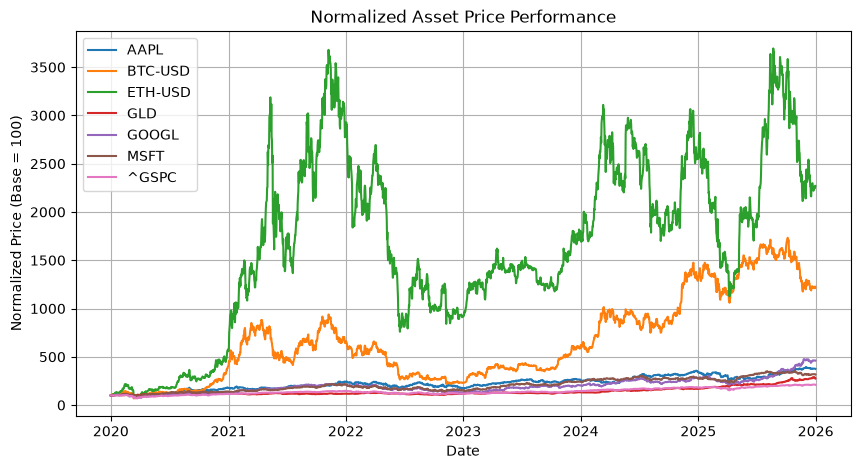

In [15]:
plt.figure(figsize=(10, 5))

for column in normalized_prices.columns:
    plt.plot(
        normalized_prices.index,
        normalized_prices[column],
        label=column
    )

plt.title("Normalized Asset Price Performance")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Base = 100)")
plt.legend()
plt.grid(True)
plt.show() 

In [16]:
risk_return = pd.DataFrame({
    "Average Daily Return": returns.mean(),
    "Daily Risk": returns.std()
})

risk_return["Annual Return"] = risk_return["Average Daily Return"] * 252
risk_return["Annual Risk"] = risk_return["Daily Risk"] * (252 ** 0.5)

display(risk_return) 

,Average Daily Return,Daily Risk,Annual Return,Annual Risk
Ticker,,,,
AAPL,0.000741,0.016624,0.186802,0.263902
BTC-USD,0.001658,0.031911,0.417920,0.506567
ETH-USD,0.002352,0.042737,0.592813,0.678427
GLD,0.000499,0.008544,0.125717,0.135626
GOOGL,0.000841,0.016972,0.212054,0.269418
MSFT,0.000646,0.015441,0.162780,0.245121
^GSPC,0.000399,0.010935,0.100531,0.173593


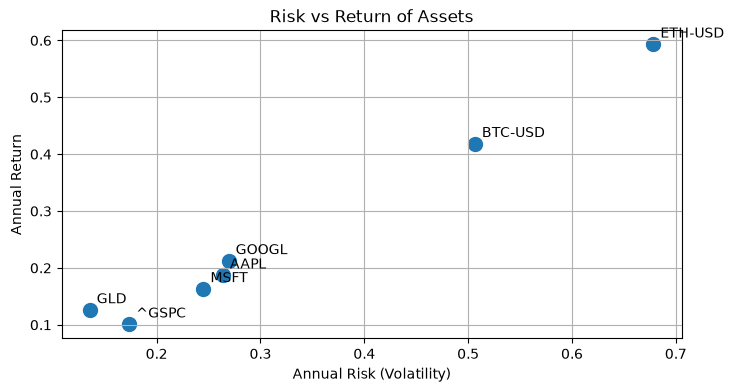

In [17]:
plt.figure(figsize=(8, 4))

plt.scatter(
    risk_return["Annual Risk"],
    risk_return["Annual Return"],
    s=100
)

for asset in risk_return.index:
    plt.annotate(
        asset,
        (
            risk_return.loc[asset, "Annual Risk"],
            risk_return.loc[asset, "Annual Return"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Risk vs Return of Assets")
plt.xlabel("Annual Risk (Volatility)")
plt.ylabel("Annual Return")
plt.grid(True)
plt.show()

In [18]:
correlation_matrix = returns.corr()

print("Correlation Matrix:")
display(correlation_matrix) 

Correlation Matrix:


Ticker,AAPL,BTC-USD,ETH-USD,GLD,GOOGL,MSFT,^GSPC
Ticker,,,,,,,
AAPL,1.000000,0.262133,0.270574,0.104331,0.623477,0.709395,0.783081
BTC-USD,0.262133,1.000000,0.813388,0.128873,0.281405,0.311482,0.352624
ETH-USD,0.270574,0.813388,1.000000,0.114572,0.294369,0.302269,0.355540
GLD,0.104331,0.128873,0.114572,1.000000,0.115305,0.093172,0.132699
GOOGL,0.623477,0.281405,0.294369,0.115305,1.000000,0.700417,0.725702
MSFT,0.709395,0.311482,0.302269,0.093172,0.700417,1.000000,0.806968
^GSPC,0.783081,0.352624,0.355540,0.132699,0.725702,0.806968,1.000000


In [19]:
# Create Client Portfolio

client_portfolio = pd.DataFrame({
    "Asset": [
        "BTC-USD",
        "ETH-USD",
        "AAPL",
        "MSFT",
        "GOOGL",
        "GLD"
    ],
    
    "Quantity": [
        0.5,
        2,
        10,
        5,
        5,
        20
    ],
    
    "Buy_Price": [
        5000000,
        200000,
        15000,
        35000,
        12000,
        4500
    ]
})

display(client_portfolio)

,Asset,Quantity,Buy_Price
0,BTC-USD,0.5,5000000
1,ETH-USD,2.0,200000
2,AAPL,10.0,15000
3,MSFT,5.0,35000
4,GOOGL,5.0,12000
5,GLD,20.0,4500


In [20]:
# Calculate Investment Amount

client_portfolio["Investment"] = (
    client_portfolio["Quantity"] *
    client_portfolio["Buy_Price"]
)

print("Client Investment Details:")
display(client_portfolio) 

Client Investment Details:


,Asset,Quantity,Buy_Price,Investment
0,BTC-USD,0.5,5000000,2500000.0
1,ETH-USD,2.0,200000,400000.0
2,AAPL,10.0,15000,150000.0
3,MSFT,5.0,35000,175000.0
4,GOOGL,5.0,12000,60000.0
5,GLD,20.0,4500,90000.0


In [21]:
#  Get Latest Market Prices

import yfinance as yf

assets = client_portfolio["Asset"].tolist()

latest_data = yf.download(
    assets,
    period="5d",
    auto_adjust=True,
    progress=False
)

latest_prices = latest_data["Close"].ffill().iloc[-1]

print("Latest Market Prices (USD):")
display(latest_prices)

Latest Market Prices (USD):


Ticker
AAPL         336.310699
BTC-USD    84273.640625
ETH-USD     2692.840088
GLD          381.049988
GOOGL        351.579987
MSFT         518.244995
Name: 2026-09-30 00:00:00, dtype: float64

In [23]:
# Get USD to INR Exchange Rate

usd_inr_data = yf.download(
    "USDINR=X",
    period="5d",
    auto_adjust=True,
    progress=False
)

usd_inr = usd_inr_data["Close"].ffill().iloc[-1]

print("Latest USD to INR Exchange Rate:") 
display(usd_inr) 

Latest USD to INR Exchange Rate:


Ticker
USDINR=X    95.82
Name: 2026-09-30 00:00:00, dtype: float64

In [24]:
#Fix USD to INR conversion

usd_inr_rate = float(usd_inr.iloc[0])

print("USD to INR Rate:", usd_inr_rate)

latest_prices_inr = latest_prices * usd_inr_rate

print("\nLatest Market Prices (INR):")
display(latest_prices_inr)

USD to INR Rate: 95.81999969482422

Latest Market Prices (INR):


Ticker
AAPL       3.222529e+04
BTC-USD    8.075100e+06
ETH-USD    2.580279e+05
GLD        3.651221e+04
GOOGL      3.368839e+04
MSFT       4.965824e+04
Name: 2026-09-30 00:00:00, dtype: float64

In [25]:
#Calculating Current Portfolio Value

client_portfolio["Current_Price"] = (
    client_portfolio["Asset"].map(latest_prices_inr)
)

client_portfolio["Current_Value"] = (
    client_portfolio["Quantity"] *
    client_portfolio["Current_Price"]
)

display(client_portfolio) 

,Asset,Quantity,Buy_Price,Investment,Current_Price,Current_Value
0,BTC-USD,0.5,5000000,2500000.0,8.075100e+06,4.037550e+06
1,ETH-USD,2.0,200000,400000.0,2.580279e+05,5.160559e+05
2,AAPL,10.0,15000,150000.0,3.222529e+04,3.222529e+05
3,MSFT,5.0,35000,175000.0,4.965824e+04,2.482912e+05
4,GOOGL,5.0,12000,60000.0,3.368839e+04,1.684420e+05
5,GLD,20.0,4500,90000.0,3.651221e+04,7.302442e+05


In [26]:
#Calculate Profit / Loss

client_portfolio["Profit_Loss"] = (
    client_portfolio["Current_Value"] -
    client_portfolio["Investment"]
)

client_portfolio["Profit_Loss_%"] = (
    client_portfolio["Profit_Loss"] /
    client_portfolio["Investment"]
) * 100

print("Client Portfolio Profit/Loss:")
display(client_portfolio) 

Client Portfolio Profit/Loss:


,Asset,Quantity,Buy_Price,Investment,Current_Price,Current_Value,Profit_Loss,Profit_Loss_%
0,BTC-USD,0.5,5000000,2500000.0,8.075100e+06,4.037550e+06,1.537550e+06,61.502004
1,ETH-USD,2.0,200000,400000.0,2.580279e+05,5.160559e+05,1.160559e+05,29.013968
2,AAPL,10.0,15000,150000.0,3.222529e+04,3.222529e+05,1.722529e+05,114.835274
3,MSFT,5.0,35000,175000.0,4.965824e+04,2.482912e+05,7.329118e+04,41.880672
4,GOOGL,5.0,12000,60000.0,3.368839e+04,1.684420e+05,1.084420e+05,180.736618
5,GLD,20.0,4500,90000.0,3.651221e+04,7.302442e+05,6.402442e+05,711.382438


In [27]:
#Total Portfolio Summary

total_investment = client_portfolio["Investment"].sum()
total_current_value = client_portfolio["Current_Value"].sum()
total_profit_loss = client_portfolio["Profit_Loss"].sum()

total_return = (
    total_profit_loss / total_investment
) * 100

print("CLIENT PORTFOLIO SUMMARY------>")

print(f"Total Investment   : ₹{total_investment:,.2f}")
print(f"Current Value      : ₹{total_current_value:,.2f}")
print(f"Total Profit/Loss  : ₹{total_profit_loss:,.2f}")
print(f"Portfolio Return   : {total_return:.2f}%") 

CLIENT PORTFOLIO SUMMARY------>
Total Investment   : ₹3,375,000.00
Current Value      : ₹6,022,836.24
Total Profit/Loss  : ₹2,647,836.24
Portfolio Return   : 78.45%


In [28]:
# Classifing the Assets according to crypto, stocks and gold

def classify_asset(asset):
    if asset in ["BTC-USD", "ETH-USD"]:
        return "Crypto"
    elif asset in ["AAPL", "MSFT", "GOOGL"]:
        return "Stock"
    elif asset == "GLD":
        return "Gold"
    else:
        return "Other"


client_portfolio["Asset_Type"] = (
    client_portfolio["Asset"].apply(classify_asset)
)

display(client_portfolio) 

,Asset,Quantity,Buy_Price,Investment,Current_Price,Current_Value,Profit_Loss,Profit_Loss_%,Asset_Type
0,BTC-USD,0.5,5000000,2500000.0,8.075100e+06,4.037550e+06,1.537550e+06,61.502004,Crypto
1,ETH-USD,2.0,200000,400000.0,2.580279e+05,5.160559e+05,1.160559e+05,29.013968,Crypto
2,AAPL,10.0,15000,150000.0,3.222529e+04,3.222529e+05,1.722529e+05,114.835274,Stock
3,MSFT,5.0,35000,175000.0,4.965824e+04,2.482912e+05,7.329118e+04,41.880672,Stock
4,GOOGL,5.0,12000,60000.0,3.368839e+04,1.684420e+05,1.084420e+05,180.736618,Stock
5,GLD,20.0,4500,90000.0,3.651221e+04,7.302442e+05,6.402442e+05,711.382438,Gold


In [29]:
# Profit & Loss Display by Asset Type

category_summary = client_portfolio.groupby("Asset_Type").agg({
    "Investment": "sum",
    "Current_Value": "sum",
    "Profit_Loss": "sum"
})

category_summary["Profit_Loss_%"] = (
    category_summary["Profit_Loss"] /
    category_summary["Investment"]
) * 100

print("P&L BY ASSET TYPE----->")
display(category_summary) 

P&L BY ASSET TYPE----->


,Investment,Current_Value,Profit_Loss,Profit_Loss_%
Asset_Type,,,,
Crypto,2900000.0,4.553606e+06,1.653606e+06,57.020896
Gold,90000.0,7.302442e+05,6.402442e+05,711.382438
Stock,385000.0,7.389861e+05,3.539861e+05,91.944431


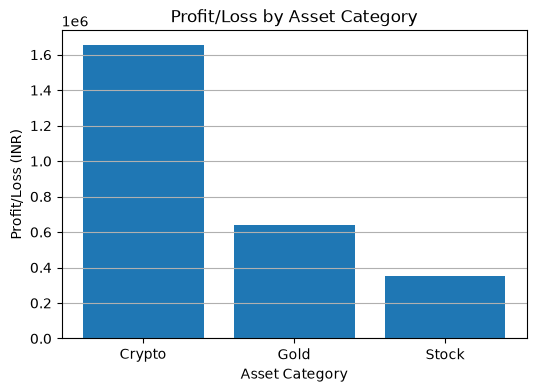

In [30]:
# Profit & Loss Visualization by Asset Category 

plt.figure(figsize=(6, 4))

plt.bar(
    category_summary.index,
    category_summary["Profit_Loss"]
)

plt.title("Profit/Loss by Asset Category")
plt.xlabel("Asset Category")
plt.ylabel("Profit/Loss (INR)")
plt.grid(axis="y")

plt.show() 

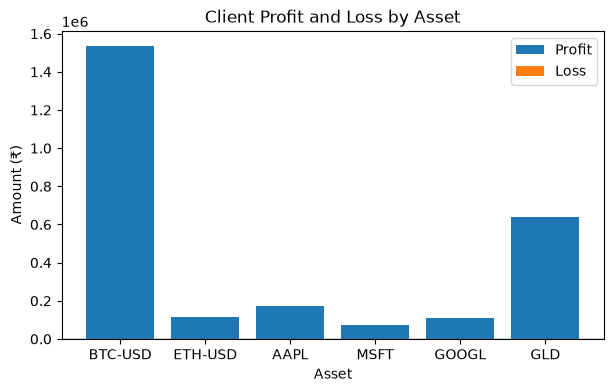

In [31]:
plt.figure(figsize=(7, 4))

profit = client_portfolio["Profit_Loss"].clip(lower=0)
loss = client_portfolio["Profit_Loss"].clip(upper=0)

x = range(len(client_portfolio))

plt.bar(x, profit, label="Profit")
plt.bar(x, loss, label="Loss")

plt.axhline(0, linewidth=1)

plt.xticks(x, client_portfolio["Asset"])
plt.title("Client Profit and Loss by Asset")
plt.xlabel("Asset")
plt.ylabel("Amount (₹)")
plt.legend()

plt.show()  

In [32]:
# Calculate Historical Portfolio Value in INR

# Get quantity of each asset
portfolio_quantities = client_portfolio.set_index("Asset")["Quantity"]

# Calculate portfolio value using historical prices
historical_portfolio = prices * portfolio_quantities

# Calculate total portfolio value for each date
historical_portfolio_value = historical_portfolio.sum(axis=1)

# Convert USD value to INR
historical_portfolio_value_inr = (
    historical_portfolio_value * usd_inr_rate
)

print("Historical Portfolio Value in INR:")
display(historical_portfolio_value_inr.head()) 

Historical Portfolio Value in INR:


Date
2020-01-01    820226.163550
2020-01-02    809289.681154
2020-01-03    829718.076402
2020-01-04    833041.262424
2020-01-05    833304.302476
Freq: D, dtype: float64

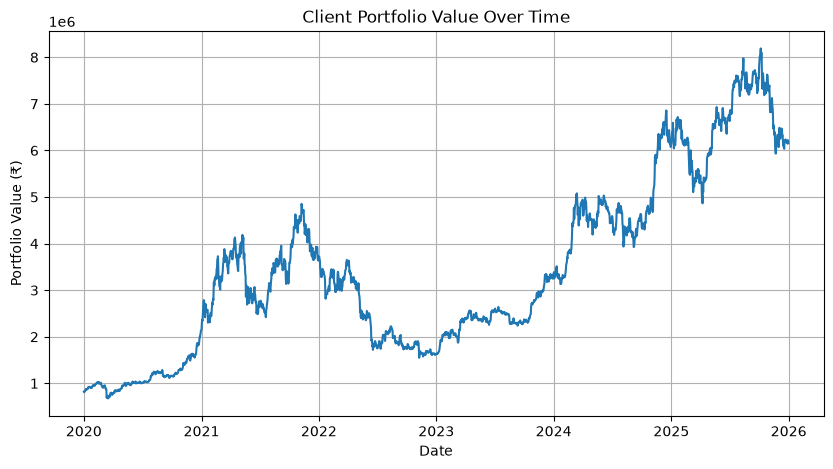

In [33]:
# Historical Portfolio Performance Graph

plt.figure(figsize=(10, 5))

plt.plot(
    historical_portfolio_value_inr.index,
    historical_portfolio_value_inr
)

plt.title("Client Portfolio Value Over Time")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (₹)")

plt.grid(True)
plt.show() 

In [34]:
# Portfolio Risk Analysis

# Calculate daily portfolio value in USD
portfolio_daily_value = historical_portfolio.sum(axis=1)

# Calculate daily portfolio returns
portfolio_returns = portfolio_daily_value.pct_change().dropna()

# Calculate average daily return
average_daily_return = portfolio_returns.mean()

# Calculate annual return
annual_return = average_daily_return * 252

# Calculate annual risk (volatility)
annual_risk = portfolio_returns.std() * (252 ** 0.5)

print("PORTFOLIO RISK ANALYSIS ------>")

print(f"Average Daily Return : {average_daily_return * 100:.2f}%")
print(f"Annual Return        : {annual_return * 100:.2f}%")
print(f"Annual Risk          : {annual_risk * 100:.2f}%")  

PORTFOLIO RISK ANALYSIS ------>
Average Daily Return : 0.12%
Annual Return        : 30.74%
Annual Risk          : 38.71%


In [35]:
# Maximum Drawdown

portfolio_peak = historical_portfolio_value_inr.cummax()

drawdown = (
    historical_portfolio_value_inr - portfolio_peak
) / portfolio_peak * 100

maximum_drawdown = drawdown.min()

print("MAXIMUM DRAWDOWN------>")
print(f"Maximum Drawdown: {maximum_drawdown:.2f}%")  

MAXIMUM DRAWDOWN------>
Maximum Drawdown: -68.09%


In [36]:
# Prepare Bitcoin data for Machine Learning

btc = prices["BTC-USD"].copy()

ml_data = pd.DataFrame()

# Current price
ml_data["Price"] = btc

# Daily return
ml_data["Return"] = btc.pct_change(fill_method=None)

# Previous day's return
ml_data["Previous_Return"] = ml_data["Return"].shift(1)

# 5-day average return
ml_data["Return_5D"] = ml_data["Return"].rolling(5).mean()

# 20-day average return
ml_data["Return_20D"] = ml_data["Return"].rolling(20).mean()

# 20-day volatility
ml_data["Volatility_20D"] = ml_data["Return"].rolling(20).std()

# Remove missing values
ml_data = ml_data.dropna()

print("Bitcoin ML Dataset:")
display(ml_data.head())  

Bitcoin ML Dataset:


,Price,Return,Previous_Return,Return_5D,Return_20D,Volatility_20D
Date,,,,,,
2020-01-21,8745.894531,0.010194,-0.005582,0.000646,0.010203,0.030509
2020-01-22,8680.875977,-0.007434,0.010194,-0.005547,0.011322,0.029352
2020-01-23,8406.515625,-0.031605,-0.007434,-0.012176,0.007169,0.029251
2020-01-24,8445.434570,0.004630,-0.031605,-0.005960,0.006953,0.029253
2020-01-25,8367.847656,-0.009187,0.004630,-0.006681,0.006489,0.029441


In [37]:
# Create the target variable

ml_data["Next_Day_Return"] = (
    ml_data["Return"].shift(-1)
)

# Remove the last row because its next-day return is unknown
ml_data = ml_data.dropna()

print("ML Dataset with Target:")
display(ml_data.head()) 

ML Dataset with Target:


,Price,Return,Previous_Return,Return_5D,Return_20D,Volatility_20D,Next_Day_Return
Date,,,,,,,
2020-01-21,8745.894531,0.010194,-0.005582,0.000646,0.010203,0.030509,-0.007434
2020-01-22,8680.875977,-0.007434,0.010194,-0.005547,0.011322,0.029352,-0.031605
2020-01-23,8406.515625,-0.031605,-0.007434,-0.012176,0.007169,0.029251,0.004630
2020-01-24,8445.434570,0.004630,-0.031605,-0.005960,0.006953,0.029253,-0.009187
2020-01-25,8367.847656,-0.009187,0.004630,-0.006681,0.006489,0.029441,0.027365


In [38]:
# Split data into training and testing

features = [
    "Price",
    "Previous_Return",
    "Return_5D",
    "Return_20D",
    "Volatility_20D"
]

X = ml_data[features]
y = ml_data["Next_Day_Return"]

# Use 80% for training and 20% for testing
split = int(len(ml_data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test)) 

Training samples: 1736
Testing samples : 435


In [39]:
#Train Random Forest Model

from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!") 

Random Forest model trained successfully!


In [40]:
# Make predictions

y_pred = rf_model.predict(X_test)

print("Actual Returns:")
print(y_test.head())

print("\nPredicted Returns:")
print(y_pred[:5])

Actual Returns:
Date
2024-10-22   -0.013794
2024-10-23    0.026024
2024-10-24   -0.022280
2024-10-25    0.005586
2024-10-26    0.013648
Freq: D, Name: Next_Day_Return, dtype: float64

Predicted Returns:
[-0.02761427 -0.01120204 -0.00991866 -0.00622264 -0.02386664]


In [41]:
#Evaluate Random Forest Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("RANDOM FOREST MODEL EVALUATION------>")

print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.4f}") 

RANDOM FOREST MODEL EVALUATION------>
MAE  : 0.020333
RMSE : 0.026442
R²   : -0.3188


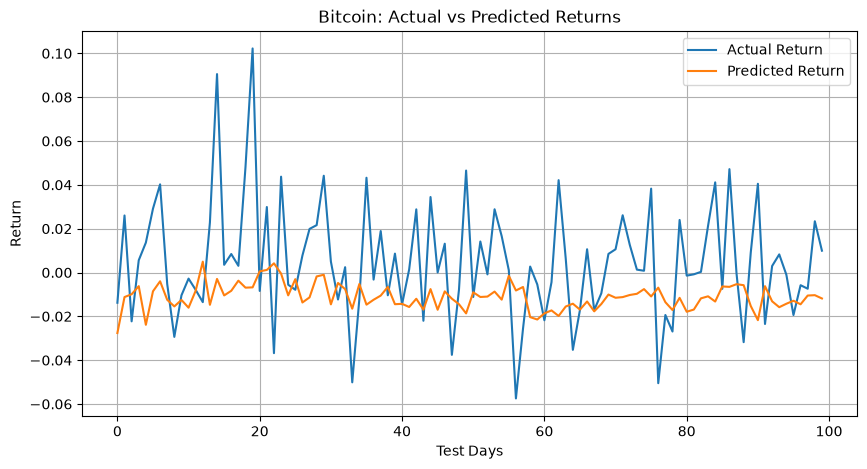

In [42]:
# Actual vs Predicted Returns

plt.figure(figsize=(10, 5))

plt.plot(
    y_test.values[:100],
    label="Actual Return"
)

plt.plot(
    y_pred[:100],
    label="Predicted Return"
)

plt.title("Bitcoin: Actual vs Predicted Returns")
plt.xlabel("Test Days")
plt.ylabel("Return")
plt.legend()
plt.grid(True)

plt.show() 

In [46]:
# Prepare data for K-Means

from sklearn.cluster import KMeans

kmeans_data = risk_return[[
    "Annual Return",
    "Annual Risk"
]].copy()

print("Data for K-Means:")
display(kmeans_data)  

Data for K-Means:


,Annual Return,Annual Risk
Ticker,,
AAPL,0.186802,0.263902
BTC-USD,0.417920,0.506567
ETH-USD,0.592813,0.678427
GLD,0.125717,0.135626
GOOGL,0.212054,0.269418
MSFT,0.162780,0.245121
^GSPC,0.100531,0.173593


In [47]:
# Apply K-Means Clustering

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_data["Cluster"] = kmeans.fit_predict(kmeans_data)

print("K-Means Clustering Result:")
display(kmeans_data) 

K-Means Clustering Result:


,Annual Return,Annual Risk,Cluster
Ticker,,,
AAPL,0.186802,0.263902,1
BTC-USD,0.417920,0.506567,2
ETH-USD,0.592813,0.678427,0
GLD,0.125717,0.135626,1
GOOGL,0.212054,0.269418,1
MSFT,0.162780,0.245121,1
^GSPC,0.100531,0.173593,1


In [48]:
# Analyze the Clusters

cluster_summary = kmeans_data.groupby("Cluster").agg({
    "Annual Return": "mean",
    "Annual Risk": "mean"
})

print("CLUSTER SUMMARY------->")
display(cluster_summary) 

CLUSTER SUMMARY------->


,Annual Return,Annual Risk
Cluster,,
0,0.592813,0.678427
1,0.157577,0.217532
2,0.417920,0.506567


In [49]:
#Assign Risk Group Names

risk_mapping = {
    0: "High Risk",
    1: "Low Risk",
    2: "Medium Risk"
}

kmeans_data["Risk_Group"] = (
    kmeans_data["Cluster"].map(risk_mapping)
)

print("ASSET RISK GROUPS----->")
display(kmeans_data) 

ASSET RISK GROUPS----->


,Annual Return,Annual Risk,Cluster,Risk_Group
Ticker,,,,
AAPL,0.186802,0.263902,1,Low Risk
BTC-USD,0.417920,0.506567,2,Medium Risk
ETH-USD,0.592813,0.678427,0,High Risk
GLD,0.125717,0.135626,1,Low Risk
GOOGL,0.212054,0.269418,1,Low Risk
MSFT,0.162780,0.245121,1,Low Risk
^GSPC,0.100531,0.173593,1,Low Risk


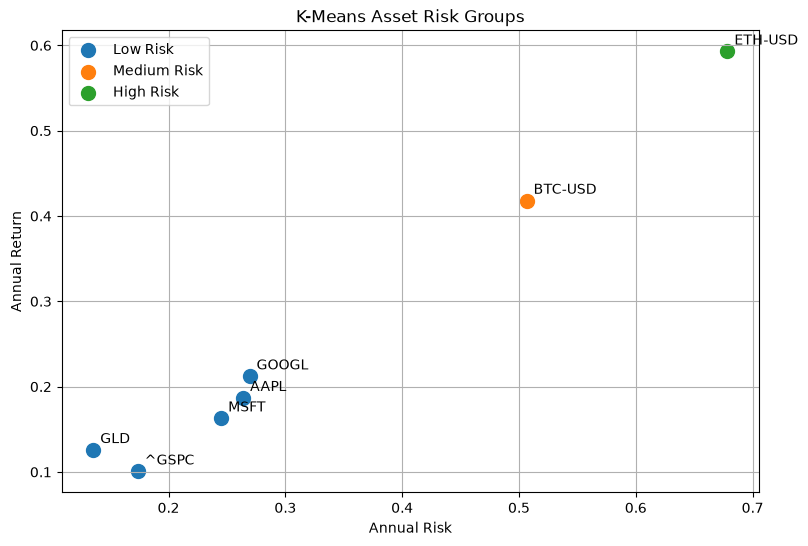

In [50]:
# K-Means Risk Group Graph

plt.figure(figsize=(9, 6))

for group in kmeans_data["Risk_Group"].unique():

    group_data = kmeans_data[
        kmeans_data["Risk_Group"] == group
    ]

    plt.scatter(
        group_data["Annual Risk"],
        group_data["Annual Return"],
        s=100,
        label=group
    )

    for asset in group_data.index:
        plt.annotate(
            asset,
            (
                group_data.loc[asset, "Annual Risk"],
                group_data.loc[asset, "Annual Return"]
            ),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.title("K-Means Asset Risk Groups")
plt.xlabel("Annual Risk")
plt.ylabel("Annual Return")
plt.legend()
plt.grid(True)

plt.show()  

In [1]:
#The LSTM(Long Short Term Memeory) (the part DL(Deep learning)) is continued in Google Colab.....

In [12]:
# INVESTMENT PORTFOLIO MANAGEMENT SYSTEM
import yfinance as yf
import pandas as pd
import numpy as np

# Client Portfolio
client_portfolio = pd.DataFrame({
    "Asset": ["BTC-USD","ETH-USD","AAPL","MSFT","GOOGL","GLD"],
    "Quantity": [ 0.5,2,10,5,5,20],
    "Buy_Price": [ 5000000,200000,15000,35000,12000,4500]
})

#Investment
client_portfolio["Investment"] = (
    client_portfolio["Quantity"] *
    client_portfolio["Buy_Price"]
)

# Download Latest Prices
tickers = client_portfolio["Asset"].tolist()

market_data = yf.download(
    tickers,
    period="5d",
    auto_adjust=True,
    progress=False
)

latest_prices = market_data["Close"].iloc[-1]

# USD to INR
usd_inr_data = yf.download(
    "USDINR=X",
    period="5d",
    auto_adjust=True,
    progress=False
)

# Fix yfinance Series/DataFrame format
usd_inr_rate = float(
    usd_inr_data["Close"].iloc[-1].iloc[0]
)

print(f"USD/INR Rate: ₹{usd_inr_rate:.2f}")

# Convert Prices to INR

current_prices = {}

for asset in tickers:

    price = float(latest_prices[asset])

    # Yahoo Finance prices for these assets are in USD
    current_prices[asset] = price * usd_inr_rate

client_portfolio["Current_Price"] = (
    client_portfolio["Asset"].map(current_prices)
)

# Current Value

client_portfolio["Current_Value"] = (
    client_portfolio["Quantity"] *
    client_portfolio["Current_Price"]
)

# Profit/Loss
client_portfolio["Profit_Loss"] = (
    client_portfolio["Current_Value"] -
    client_portfolio["Investment"]
)

client_portfolio["Profit_Loss_%"] = (
    client_portfolio["Profit_Loss"] /
    client_portfolio["Investment"]
) * 100

# Asset Classification
def classify_asset(asset):

    if asset in ["BTC-USD", "ETH-USD"]:
        return "Crypto"

    elif asset in ["AAPL", "MSFT", "GOOGL"]:
        return "Stock"

    elif asset == "GLD":
        return "Gold"

    return "Other"


client_portfolio["Category"] = (
    client_portfolio["Asset"].apply(classify_asset)
)

# Overall Portfolio

total_investment = client_portfolio["Investment"].sum()

total_current_value = client_portfolio["Current_Value"].sum()

total_profit_loss = client_portfolio["Profit_Loss"].sum()

total_profit_loss_percent = (
    total_profit_loss /
    total_investment
) * 100

# Category Summary

category_summary = client_portfolio.groupby("Category").agg({
    "Investment": "sum",
    "Current_Value": "sum",
    "Profit_Loss": "sum"
})

category_summary["Profit_Loss_%"] = (
    category_summary["Profit_Loss"] /
    category_summary["Investment"]
) * 100

#  Display Asset Results
print("CLIENT INVESTMENT PORTFOLIO")
display(
    client_portfolio[
        [
            "Asset",
            "Category",
            "Quantity",
            "Investment",
            "Current_Price",
            "Current_Value",
            "Profit_Loss",
            "Profit_Loss_%"
        ]
    ].round(2)
)

#  Portfolio Summary
print("PORTFOLIO SUMMARY")
print(f"Total Investment   : ₹{total_investment:,.2f}")
print(f"Current Value      : ₹{total_current_value:,.2f}")
print(f"Total Profit/Loss  : ₹{total_profit_loss:,.2f}")
print(f"Portfolio Return   : {total_profit_loss_percent:.2f}%")
#Category Performance
print("CATEGORY-WISE PERFORMANCE")
display(category_summary.round(2))
print("\nPortfolio analysis completed successfully!")  

USD/INR Rate: ₹96.31
CLIENT INVESTMENT PORTFOLIO


,Asset,Category,Quantity,Investment,Current_Price,Current_Value,Profit_Loss,Profit_Loss_%
0,BTC-USD,Crypto,0.5,2500000.0,8180823.12,4090411.56,1590411.56,63.62
1,ETH-USD,Crypto,2.0,400000.0,260915.29,521830.57,121830.57,30.46
2,AAPL,Stock,10.0,150000.0,31698.79,316987.90,166987.90,111.33
3,MSFT,Stock,5.0,175000.0,49668.82,248344.11,73344.11,41.91
4,GOOGL,Stock,5.0,60000.0,32654.04,163270.20,103270.20,172.12
5,GLD,Gold,20.0,90000.0,36892.52,737850.36,647850.36,719.83


PORTFOLIO SUMMARY
Total Investment   : ₹3,375,000.00
Current Value      : ₹6,078,694.71
Total Profit/Loss  : ₹2,703,694.71
Portfolio Return   : 80.11%
CATEGORY-WISE PERFORMANCE


,Investment,Current_Value,Profit_Loss,Profit_Loss_%
Category,,,,
Crypto,2900000.0,4612242.13,1712242.13,59.04
Gold,90000.0,737850.36,647850.36,719.83
Stock,385000.0,728602.21,343602.21,89.25



Portfolio analysis completed successfully!


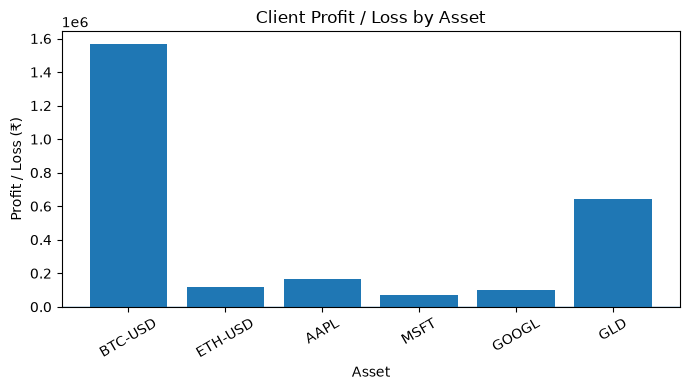

In [8]:
# CLIENT PROFIT / LOSS GRAPH
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    client_portfolio["Asset"],
    client_portfolio["Profit_Loss"]
)

plt.axhline(0, linewidth=1)

plt.title("Client Profit / Loss by Asset")
plt.xlabel("Asset")
plt.ylabel("Profit / Loss (₹)")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()  

CATEGORY-WISE PORTFOLIO VALUE


,Investment,Current_Value
Category,,
Crypto,2900000.0,4582674.76
Gold,90000.0,735336.82
Stock,385000.0,725879.70


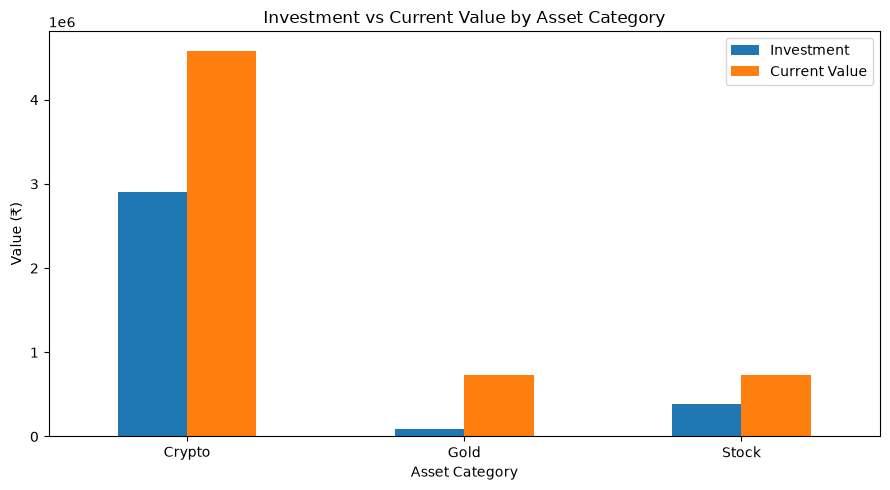

In [10]:
# CRYPTO vs STOCK vs GOLD
category_comparison = client_portfolio.groupby("Category").agg({
    "Investment": "sum",
    "Current_Value": "sum"
})

print("CATEGORY-WISE PORTFOLIO VALUE")
display(category_comparison.round(2))
# Graph
category_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Investment vs Current Value by Asset Category")
plt.xlabel("Asset Category")
plt.ylabel("Value (₹)")
plt.xticks(rotation=0)
plt.legend(["Investment", "Current Value"])

plt.tight_layout()
plt.show() 

In [13]:

# FINAL INTEGRATION

print("INVESTMENT PORTFOLIO MANAGEMENT SYSTEM")
# PORTFOLIO SUMMARY
total_investment = client_portfolio["Investment"].sum()
total_current_value = client_portfolio["Current_Value"].sum()
total_profit_loss = client_portfolio["Profit_Loss"].sum()

total_return = (
    total_profit_loss / total_investment
) * 100

print("\nPORTFOLIO SUMMARY")

print(f"Total Investment     : ₹{total_investment:,.2f}")
print(f"Current Portfolio    : ₹{total_current_value:,.2f}")
print(f"Total Profit/Loss    : ₹{total_profit_loss:,.2f}")
print(f"Overall Return       : {total_return:.2f}%")

# PROFIT / LOSS STATUS
if total_profit_loss > 0:
    print("Portfolio Status     : PROFIT")
elif total_profit_loss < 0:
    print("Portfolio Status     : LOSS")
else:
    print("Portfolio Status     : NO PROFIT / NO LOSS")

#ASSET CATEGORY SUMMARY
print("\nASSET CATEGORY SUMMARY")
category_summary = client_portfolio.groupby("Category").agg({
    "Investment": "sum",
    "Current_Value": "sum",
    "Profit_Loss": "sum"
})

category_summary["Profit_Loss_%"] = (
    category_summary["Profit_Loss"] /
    category_summary["Investment"]
) * 100

display(category_summary.round(2))

# ASSET-WISE SUMMARY
print("\nASSET-WISE PROFIT / LOSS")


display(
    client_portfolio[
        [
            "Asset",
            "Category",
            "Investment",
            "Current_Value",
            "Profit_Loss",
            "Profit_Loss_%"
        ]
    ].round(2)
)

print("INTEGRATION COMPLETED")

INVESTMENT PORTFOLIO MANAGEMENT SYSTEM

PORTFOLIO SUMMARY
Total Investment     : ₹3,375,000.00
Current Portfolio    : ₹6,078,694.71
Total Profit/Loss    : ₹2,703,694.71
Overall Return       : 80.11%
Portfolio Status     : PROFIT

ASSET CATEGORY SUMMARY


,Investment,Current_Value,Profit_Loss,Profit_Loss_%
Category,,,,
Crypto,2900000.0,4612242.13,1712242.13,59.04
Gold,90000.0,737850.36,647850.36,719.83
Stock,385000.0,728602.21,343602.21,89.25



ASSET-WISE PROFIT / LOSS


,Asset,Category,Investment,Current_Value,Profit_Loss,Profit_Loss_%
0,BTC-USD,Crypto,2500000.0,4090411.56,1590411.56,63.62
1,ETH-USD,Crypto,400000.0,521830.57,121830.57,30.46
2,AAPL,Stock,150000.0,316987.90,166987.90,111.33
3,MSFT,Stock,175000.0,248344.11,73344.11,41.91
4,GOOGL,Stock,60000.0,163270.20,103270.20,172.12
5,GLD,Gold,90000.0,737850.36,647850.36,719.83


INTEGRATION COMPLETED


In [2]:
import os

print("Current notebook folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current notebook folder:
C:\Users\TRICON

Files in this folder:
['.claude', '.claude.json', '.copilot', '.eclipse', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.m2', '.p2', '.vscode', '.vscode-shared', '3D Objects', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'eclipse', 'eclipse-workspace', 'Favorites', 'IntelGraphicsProfiles', 'Investment_Portfolio.ipynb', 'Links', 'Local Settings', 'lstm_env', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{dded004a-21a1-11f0-be6e-e76833a57023}.TM.blf', 'NTUSER.DAT{dded004a-21a1-11f0-be6e-e76833a57023}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{dded004a-21a1-11f0-be6e-e76833a57023}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'Python latest Version and Address.ipynb', 'Recent', 'Saved Games', 'ScStore', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'Videos', 'W

In [3]:
import os

downloads_path = r"C:\Users\TRICON\Downloads"

print(os.listdir(downloads_path))

['!!bUNsi_qhlogs.txt', '!qhlogs.doc', '11zon_compressed.zip', '1K1qEzO_qhlogs.csv', '520260094734_srodigitalsign_deed.pdf', '520260094734_sroindex2signdocument.pdf', 'ACFrOgAOZyzv0MUjgORmK19tywuS-KG0pEWqmeihT85_4aAszH1beCJJbUzTk-YUfJzEMuwQlhejEUfnuLlzVlW7ihciw1gUs6UvKcWfb5remPHFEhi9EbWDE-CkktjQF8DYhgnBVSHKYPwd1WzaLmQkJdLWowg7LCIyorQSSQ==.pdf', 'adboI4q_qhlogs.doc', 'answer.docx', 'apache-tomcat-10.1.55-windows-x64', 'apache-tomcat-10.1.55-windows-x64.zip', 'association rule mining example.docx', 'Autoencoder_Anomaly_Results.csv', 'ChatGPT Image Jul 27, 2026, 12_05_00 PM.png', 'CV_Updated.pdf', 'dbms.zip', 'dbmsadd6.zip', 'desktop.ini', 'DS CIE2 Question Bank.pdf', 'eclipse-inst-jre-win64.exe', 'Embarcadero_Dev-Cpp_6.3_TDM-GCC_9.2_Setup.zip', 'employee_salary.csv', 'file (1).pdf', 'HealthLockerUI.zip', 'HR PPT.pptx', 'INDEX-II.pdf', 'IntelliHireX_Rep_CReate_vaish.docx', 'Investment_Portfolio.ipynb', 'KASHVEE CHE PUSTAK', 'Medical_DigiLocker_Research_Papers_Paragraph_Format.pptx', 'ml_po

In [4]:
import pandas as pd

csv_path = r"C:\Users\TRICON\Downloads\Autoencoder_Anomaly_Results.csv"

anomalies = pd.read_csv(csv_path)
anomalies["Date"] = pd.to_datetime(anomalies["Date"])

print("Autoencoder results loaded successfully!")
print("Total observations:", len(anomalies))
print("Potential anomalies:", int(anomalies["Anomaly"].astype(str).str.lower().eq("true").sum()))

display(anomalies.head())

Autoencoder results loaded successfully!
Total observations: 437
Potential anomalies: 48


C:\Users\TRICON\AppData\Local\Temp\ipykernel_40904\2200740401.py:6: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  anomalies["Date"] = pd.to_datetime(anomalies["Date"])


,Date,Reconstruction_Error,Anomaly
0,2024-10-21,0.102725,False
1,2024-10-22,0.212555,False
2,2024-10-23,0.083214,False
3,2024-10-24,0.034091,False
4,2024-10-25,0.066540,False


In [5]:

# Fix date format
anomalies["Date"] = pd.to_datetime(
    anomalies["Date"],
    dayfirst=True
)

# Convert anomaly values to True/False
anomalies["Anomaly"] = (
    anomalies["Anomaly"].astype(str).str.lower() == "true"
)

print("AUTOENCODER ANOMALY DETECTION SUMMARY")
print("-------------------------------------")
print("Total observations:", len(anomalies))
print("Normal observations:", int((~anomalies["Anomaly"]).sum()))
print("Potential anomalies:", int(anomalies["Anomaly"].sum()))
print("Start date:", anomalies["Date"].min().date())
print("End date:", anomalies["Date"].max().date())

display(anomalies.head()) 

AUTOENCODER ANOMALY DETECTION SUMMARY
-------------------------------------
Total observations: 437
Normal observations: 389
Potential anomalies: 48
Start date: 2024-10-21
End date: 2025-12-31


,Date,Reconstruction_Error,Anomaly
0,2024-10-21,0.102725,False
1,2024-10-22,0.212555,False
2,2024-10-23,0.083214,False
3,2024-10-24,0.034091,False
4,2024-10-25,0.066540,False


In [6]:

# Prepare Autoencoder results for integration

# Correctly parse dates in day-month-year format
anomalies["Date"] = pd.to_datetime(
    anomalies["Date"],
    dayfirst=True
)

# Convert Anomaly column to True/False
anomalies["Anomaly"] = (
    anomalies["Anomaly"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

# Select only potential anomalies
anomaly_dates = anomalies[anomalies["Anomaly"] == True].copy()

print("AUTOENCODER INTEGRATION CHECK")
print("-" * 40)
print("Total observations:", len(anomalies))
print("Potential anomalies:", len(anomaly_dates))
print("First anomaly dates:")
display(anomaly_dates.head(10))

print("Date range:")
print(anomalies["Date"].min(), "to", anomalies["Date"].max())


AUTOENCODER INTEGRATION CHECK
----------------------------------------
Total observations: 437
Potential anomalies: 48
First anomaly dates:


,Date,Reconstruction_Error,Anomaly
10,2024-10-31,0.531154,True
35,2024-11-25,1.334981,True
98,2025-01-27,2.065586,True
100,2025-01-29,0.448074,True
101,2025-01-30,0.813734,True
102,2025-01-31,0.464408,True
133,2025-03-03,0.587555,True
164,2025-04-03,1.006104,True
165,2025-04-04,0.830361,True
166,2025-04-05,0.458972,True


Date range:
2024-10-21 00:00:00 to 2025-12-31 00:00:00


In [7]:

# FINAL INTEGRATION: AUTOENCODER RESULTS

print("=" * 55)
print(" AI-BASED INVESTMENT PORTFOLIO MANAGEMENT SYSTEM")
print("=" * 55)

print("\nAUTOENCODER ANOMALY DETECTION")
print("-" * 40)

total_observations = len(anomalies)
total_anomalies = int(anomalies["Anomaly"].sum())
normal_observations = total_observations - total_anomalies

print("Total observations       :", total_observations)
print("Normal observations      :", normal_observations)
print("Potential anomalies      :", total_anomalies)
print("Anomaly percentage       :",
      round(total_anomalies / total_observations * 100, 2), "%")

print("Start date               :",
      anomalies["Date"].min().strftime("%Y-%m-%d"))
print("End date                 :",
      anomalies["Date"].max().strftime("%Y-%m-%d"))

print("\nFIRST 10 DETECTED ANOMALIES")
print("-" * 40)

display(
    anomalies[anomalies["Anomaly"]]
    [["Date", "Reconstruction_Error", "Anomaly"]]
    .head(10)
    .reset_index(drop=True)
)

print("\nAUTOENCODER INTEGRATION COMPLETED") 

 AI-BASED INVESTMENT PORTFOLIO MANAGEMENT SYSTEM

AUTOENCODER ANOMALY DETECTION
----------------------------------------
Total observations       : 437
Normal observations      : 389
Potential anomalies      : 48
Anomaly percentage       : 10.98 %
Start date               : 2024-10-21
End date                 : 2025-12-31

FIRST 10 DETECTED ANOMALIES
----------------------------------------


,Date,Reconstruction_Error,Anomaly
0,2024-10-31,0.531154,True
1,2024-11-25,1.334981,True
2,2025-01-27,2.065586,True
3,2025-01-29,0.448074,True
4,2025-01-30,0.813734,True
5,2025-01-31,0.464408,True
6,2025-03-03,0.587555,True
7,2025-04-03,1.006104,True
8,2025-04-04,0.830361,True
9,2025-04-05,0.458972,True



AUTOENCODER INTEGRATION COMPLETED
